# Module 12: Modern Analytics Visualization

In this notebook, we compare the three major ways to visualize geographic data on the web:
1. **Traditional Raster/GeoJSON**: The legacy approach (bottlenecks & dead pixels).
2. **Vector Tiles**: The middle ground (interactive but clipped/complex).
3. **Modern Cloud-Native**: The GPU-accelerated path (analytical integrity & speed).

### Setup Dependencies

In [1]:
import duckdb
import geopandas as gpd
import time
import requests
import json
import matplotlib.pyplot as plt
import io
from PIL import Image
from shapely.geometry import shape
import lonboard
import mapbox_vector_tile

%matplotlib inline

print(f"All libraries loaded. Lonboard version: {lonboard.__version__}")

All libraries loaded. Lonboard version: 0.13.0


## 1. Traditional Raster & GeoJSON

Traditional apps suffer from the "GeoJSON bottleneck" where browsers struggle to parse large text files. To solve this, they usually switch to Raster Tiles (dead pixels).

Querying SF POIs...
Estimated GeoJSON size for all features: 7.88 MB

--- RASTER TILE VISUAL ---
Raster Tile Size: 38.86 KB


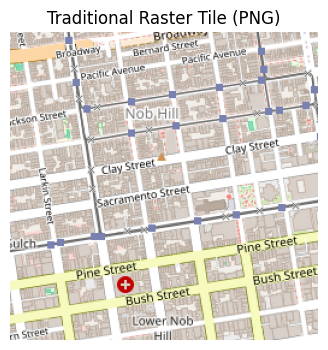

In [2]:
con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET s3_region='us-west-2';")

release = "2026-01-21.0"
places_url = f"s3://overturemaps-us-west-2/release/{release}/theme=places/type=place/*"

print("Querying SF POIs...")
query = f"""
SELECT names.primary as name, ST_AsWKB(geometry) as geom
FROM read_parquet('{places_url}')
WHERE bbox.xmin > -122.51 AND bbox.xmax < -122.35 AND bbox.ymin > 37.70 AND bbox.ymax < 37.83;
"""
df = con.execute(query).df()
gdf = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df['geom'].apply(bytes)), crs="EPSG:4326")

# Simulating GeoJSON Overhead
geojson_chunk = gdf.head(5000).drop(columns=['geom']).to_json()
print(f"Estimated GeoJSON size for all features: { (len(geojson_chunk)/5000) * len(gdf) / (1024*1024):.2f} MB")

# Fetching a Raster Tile (Dead Pixels)
print("\n--- RASTER TILE VISUAL ---")
tile_url = "https://tile.openstreetmap.org/15/5241/12663.png"
resp = requests.get(tile_url, headers={'User-Agent': 'CloudNativeTutorial/1.0'})
print(f"Raster Tile Size: {len(resp.content)/1024:.2f} KB")

# Display using PIL + Matplotlib to ensure it shows up in the notebook
tile_img = Image.open(io.BytesIO(resp.content))
plt.figure(figsize=(4, 4))
plt.imshow(tile_img)
plt.title("Traditional Raster Tile (PNG)")
plt.axis('off')
plt.show()

## 2. Vector Tiles (MVT)

Vector tiles send binary geometry, providing interactivity but adding complexity and clipping boundaries.

--- VECTOR TILE DECODING & PLOTTING ---
Decoding layer: centroids
Decoding layer: countries
Decoding layer: geolines


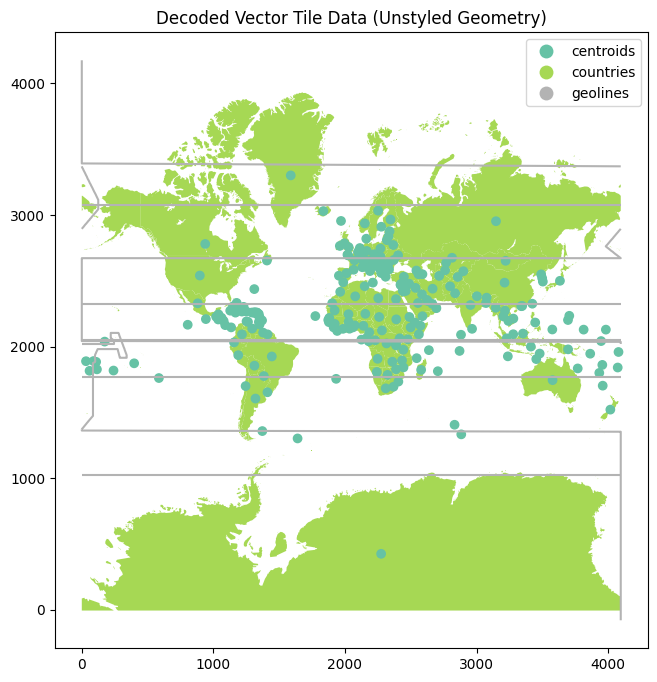

In [3]:
print("--- VECTOR TILE DECODING & PLOTTING ---")
mvt_url = "https://demotiles.maplibre.org/tiles/0/0/0.pbf"
resp = requests.get(mvt_url)
decoded = mapbox_vector_tile.decode(resp.content)

all_features = []
for layer_name, layer in decoded.items():
    print(f"Decoding layer: {layer_name}")
    for feat in layer['features']:
        geom = shape(feat['geometry'])
        props = feat['properties']
        props['layer'] = layer_name
        all_features.append({'geometry': geom, **props})

mvt_gdf = gpd.GeoDataFrame(all_features)
plt.figure(figsize=(10, 8))
mvt_gdf.plot(column='layer', legend=True, cmap='Set2', ax=plt.gca())
plt.title("Decoded Vector Tile Data (Unstyled Geometry)")
plt.show()

## 3. Modern Cloud-Native (Lonboard)

This is the fastest path. We send the raw analytical data directly to the GPU using **GeoArrow**.

In [4]:
# The REAL Lonboard magic -- this renders in your notebook!
# Fix: explicitly convert to arrow to avoid generic pandas conversion errors
layer = lonboard.ScatterplotLayer(gdf.to_arrow())
layer.get_fill_color = [0, 120, 255, 200]
layer.get_radius = 5

map_view = lonboard.Map(layer)
map_view